<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/jobsheet/JS14_244107020095_RACHMAD_FEBRIANANDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS14 — Convolutional Neural Network (CNN)

**Nama** : Rachmad Febriananda
**NIM** : 244107020095

## Dasar Teori Singkat

**Convolutional Neural Network (CNN)** adalah jaringan syaraf tiruan yang dirancang untuk data visual. Berbeda dengan ANN biasa yang meratakan citra menjadi vektor, CNN mempertahankan struktur spasial dan mengekstraksi fitur secara otomatis (tepi → tekstur → bentuk → objek).

**Blok penyusun CNN:**

1. **Convolutional layer** — menggeser *kernel/filter* (mis. 3×3) di atas citra dan menghitung dot product, menghasilkan *feature map*. Bobot kernel dipelajari, sehingga jaringan "belajar" mendeteksi pola tertentu.
2. **Padding** — menambah piksel nol di tepi citra (`same`) agar ukuran output tidak menyusut; tanpa padding disebut `valid`.
3. **Stride** — jarak pergeseran kernel. Stride 1 mempertahankan detail, stride 2 memperkecil resolusi.
4. **Fungsi aktivasi** — umumnya **ReLU** pada blok konvolusi untuk menambah non-linearitas.
5. **Pooling layer** — meringkas feature map (mis. **MaxPooling 2×2**) sehingga jumlah parameter turun dan model lebih tahan terhadap pergeseran kecil (*translation invariance*).
6. **Flattening** — mengubah feature map 2D menjadi vektor 1D.
7. **Fully connected block** — layer Dense untuk menggabungkan fitur menjadi keputusan kelas; output memakai **sigmoid** (biner) atau **softmax** (multikelas).

**Proses pembelajaran:** forward pass menghitung prediksi → loss dihitung → backpropagation menghitung gradien → optimizer (Adam) memperbarui bobot kernel dan Dense. Berbeda dengan ANN, jumlah parameter CNN jauh lebih sedikit karena kernel dipakai bersama (*weight sharing*) di seluruh posisi citra.

## PRAKTIKUM 1 — Klasifikasi Cat vs. Dog

Dataset citra kucing dan anjing yang sudah dibagi menjadi `training_set` (4.000 kucing + 4.000 anjing), `test_set` (1.000 + 1.000), serta folder `single_prediction` untuk uji prediksi satu citra. Dataset diletakkan di `dataset/js14/cats_dogs/`.

> Catatan: modul asli menggunakan `ImageDataGenerator` dan `keras.preprocessing.image`, yang **sudah dihapus/deprecated pada Keras 3**. Di notebook ini dipakai API modern `tf.keras.utils.image_dataset_from_directory` + layer augmentasi (`RandomFlip`, `RandomRotation`, `RandomZoom`), dengan hasil preprocessing yang setara (rescale 1/255, shear/zoom, horizontal flip).

In [1]:
%matplotlib inline
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['ABSL_MIN_LOG_LEVEL'] = '3'

import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models

np.random.seed(42)
tf.random.set_seed(42)
sns.set_style('whitegrid')

BASE = 'dataset/js14/cats_dogs'
train_dir = f'{BASE}/training_set'
test_dir  = f'{BASE}/test_set'
single_dir = f'{BASE}/single_prediction'

IMG_SIZE = (64, 64)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH, label_mode='binary',
    shuffle=True, seed=42)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH, label_mode='binary',
    shuffle=False)

class_names = train_ds.class_names
print('Kelas:', class_names)
print('class_indices:', {n: i for i, n in enumerate(class_names)})
print('Jumlah batch train:', len(train_ds), '| test:', len(test_ds))

Found 8000 files belonging to 2 classes.


Found 2000 files belonging to 2 classes.


Kelas: ['cats', 'dogs']
class_indices: {'cats': 0, 'dogs': 1}
Jumlah batch train: 250 | test: 63


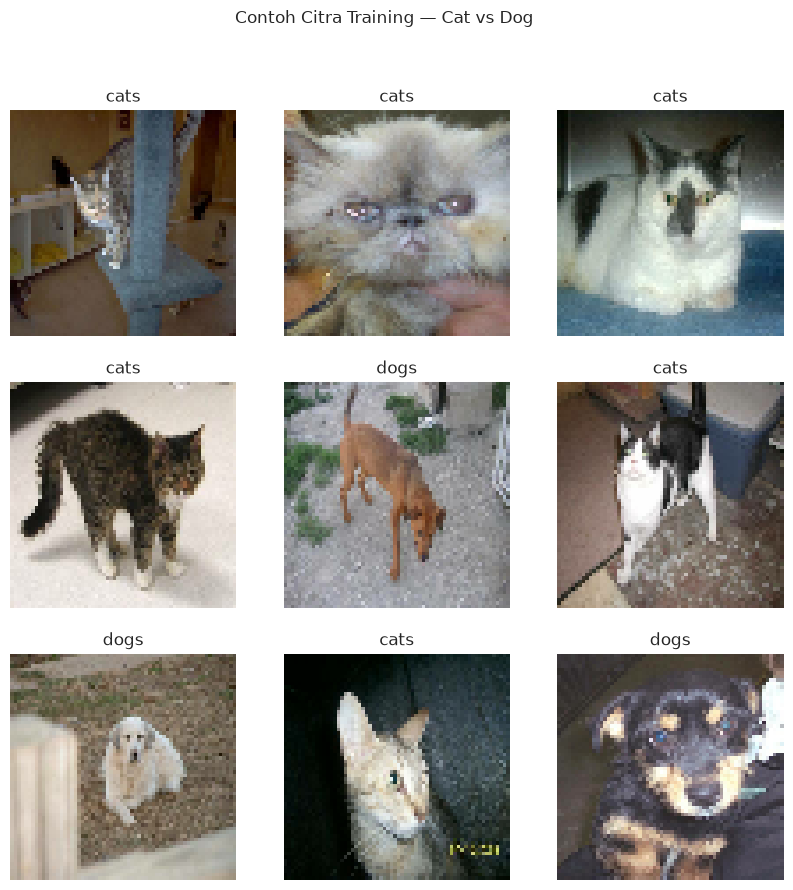

In [2]:
# Inspeksi beberapa citra training
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[int(labels[i][0])])
        plt.axis('off')
plt.suptitle('Contoh Citra Training — Cat vs Dog')
plt.show()

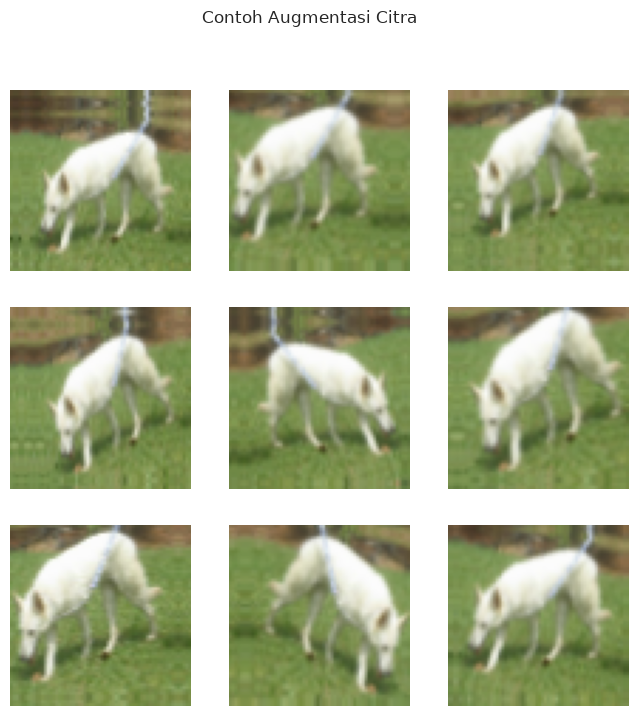

In [3]:
# Augmentasi (pengganti shear_range, zoom_range, horizontal_flip pada ImageDataGenerator)
data_augmentation = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1, 0.1),
], name='augmentasi')

# Visualisasi efek augmentasi pada satu citra
for images, labels in train_ds.take(1):
    sample = images[0:1]
    break

plt.figure(figsize=(8, 8))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented = data_augmentation(sample, training=True)
    plt.imshow(augmented[0].numpy().astype('uint8'))
    plt.axis('off')
plt.suptitle('Contoh Augmentasi Citra')
plt.show()

In [4]:
# Arsitektur CNN sesuai modul: Conv32 -> Pool -> Conv32 -> Pool -> Flatten -> Dense128 -> Dense1
tf.random.set_seed(42)
cnn = models.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    data_augmentation,
    layers.Rescaling(1./255),                      # normalisasi nilai piksel

    layers.Conv2D(filters=32, kernel_size=3, activation='relu'),
    layers.MaxPool2D(pool_size=2, strides=2),

    layers.Conv2D(filters=32, kernel_size=3, activation='relu'),
    layers.MaxPool2D(pool_size=2, strides=2),

    layers.Flatten(),
    layers.Dense(units=128, activation='relu'),
    layers.Dense(units=1, activation='sigmoid')
])

cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentasi (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Training
t0 = time.time()
history_cnn = cnn.fit(train_ds, validation_data=test_ds, epochs=25, verbose=0)
waktu_cnn = time.time() - t0
print(f'Waktu training: {waktu_cnn:.1f} detik')

test_loss, test_acc = cnn.evaluate(test_ds, verbose=0)
print(f'Loss test    : {test_loss:.4f}')
print(f'Akurasi test : {test_acc:.4f}')

Waktu training: 512.3 detik


Loss test    : 0.4643
Akurasi test : 0.7900


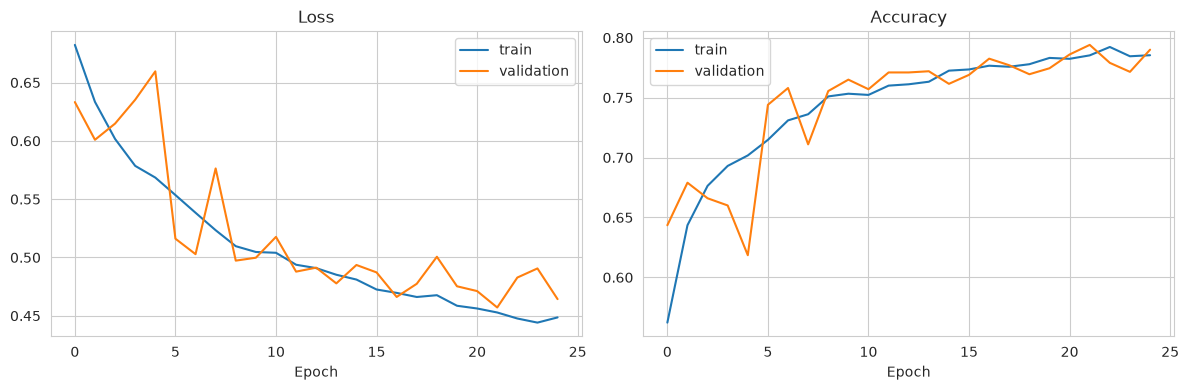

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_cnn.history['loss'], label='train')
ax[0].plot(history_cnn.history['val_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()

ax[1].plot(history_cnn.history['accuracy'], label='train')
ax[1].plot(history_cnn.history['val_accuracy'], label='validation')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout(); plt.show()

Confusion Matrix (baris=aktual, kolom=prediksi):
[[710 290]
 [130 870]]

              precision    recall  f1-score   support

        cats     0.8452    0.7100    0.7717      1000
        dogs     0.7500    0.8700    0.8056      1000

    accuracy                         0.7900      2000
   macro avg     0.7976    0.7900    0.7886      2000
weighted avg     0.7976    0.7900    0.7886      2000



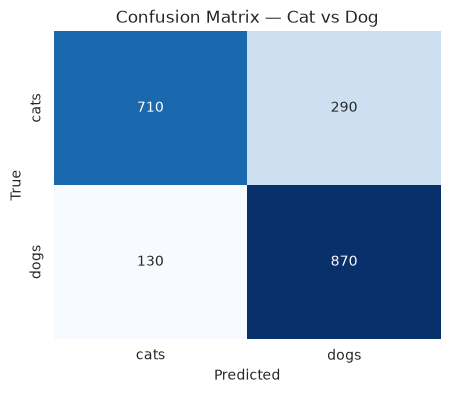

In [7]:
# Evaluasi detail: confusion matrix + classification report
from sklearn.metrics import confusion_matrix, classification_report

y_true = np.concatenate([y.numpy() for _, y in test_ds]).astype(int).ravel()
y_prob = cnn.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)
print('Confusion Matrix (baris=aktual, kolom=prediksi):')
print(cm)
print()
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion Matrix — Cat vs Dog')
plt.show()

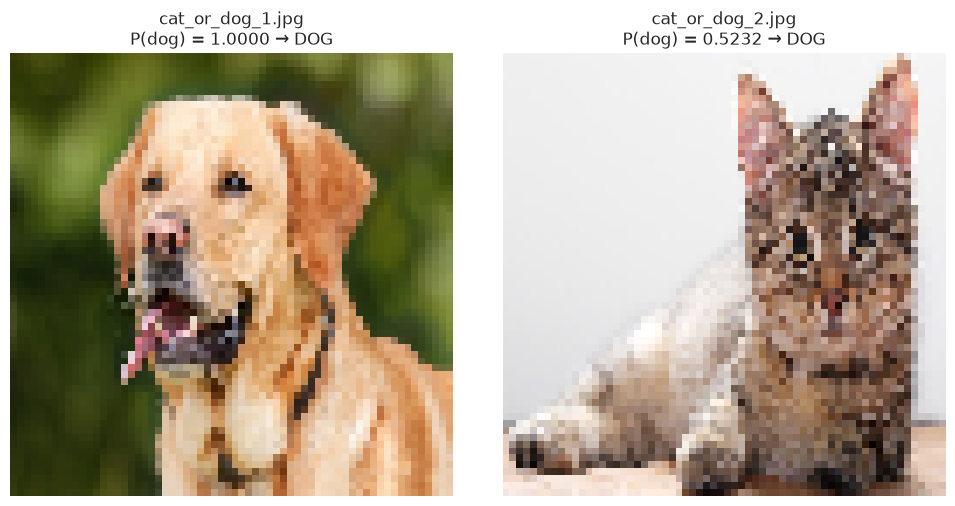

In [8]:
# Prediksi satu citra (Langkah 5 modul)
import keras

def prediksi_satu_citra(path):
    img = keras.utils.load_img(path, target_size=IMG_SIZE)
    arr = keras.utils.img_to_array(img)
    arr = np.expand_dims(arr, axis=0)
    hasil = cnn.predict(arr, verbose=0)[0][0]
    # mapping alfabetis dari image_dataset_from_directory: 0 = cat, 1 = dog
    label = 'dog' if hasil > 0.5 else 'cat'
    return img, float(hasil), label

plt.figure(figsize=(10, 5))
for i, nama in enumerate(['cat_or_dog_1.jpg', 'cat_or_dog_2.jpg']):
    path = f'{single_dir}/{nama}'
    img, prob, label = prediksi_satu_citra(path)
    plt.subplot(1, 2, i + 1)
    plt.imshow(img)
    plt.axis('off')
    plt.title(f'{nama}\nP(dog) = {prob:.4f} → {label.upper()}')
plt.tight_layout(); plt.show()

**Analisis Praktikum 1:**

- Model CNN sederhana (2 blok konvolusi 32 filter + 2 layer Dense, **813.217 parameter / ±0,81 juta**) mencapai akurasi test **0,7900** (loss 0,4643) setelah 25 epoch, dengan waktu training ±512 detik. Kurva `accuracy` dan `val_accuracy` naik bersama tanpa divergen, sehingga model belum menunjukkan overfitting berat — performanya lebih dibatasi kapasitas model dan jumlah epoch daripada oleh hafalan data.
- Nilai 0,79 sedikit di bawah 0,80. Penyebab yang paling mungkin: input diperkecil ke 64×64 dan data training hanya 8.000 citra; menambah epoch, memperbesar resolusi, atau menambah blok konvolusi akan menaikkan akurasi dengan konsekuensi waktu komputasi.
- **Augmentasi** (flip horizontal, rotasi kecil, zoom, dan translasi) berperan sebagai regularisasi: model tidak menghafal posisi/arah objek, sehingga lebih general pada data test. Ini menggantikan `shear_range`/`zoom_range`/`horizontal_flip` pada `ImageDataGenerator` yang sudah deprecated.
- **Convolution + pooling** menurunkan dimensi secara bertahap: 64×64×3 → 62×62×32 → 31×31×32 → 29×29×32 → 14×14×32, lalu di-Flatten menjadi 6.272 fitur sebelum Dense. Weight sharing pada kernel membuat jumlah parameter jauh lebih kecil dibanding ANN dengan input 64×64×3 = 12.288 neuron.
- **Sigmoid + binary crossentropy** tepat dipakai karena hanya ada dua kelas. Threshold 0.5 memetakan P(dog) > 0.5 ke "dog" dan sebaliknya ke "cat".
- Kesalahan prediksi umumnya terjadi pada citra yang ambigu (objek kecil, latar ramai, atau pose tidak biasa), bukan pada citra khas kucing/anjing.

## PRAKTIKUM 2 — Klasifikasi Multilabel Dataset CIFAR-10

Dataset CIFAR-10 berisi **60.000 citra 32×32** dalam 10 kelas (50.000 training, 10.000 testing), masing-masing 6.000 citra. Praktikum mengikuti tutorial CNN TensorFlow.

> Catatan teknis: mirror `https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz` yang dipakai `tf.keras.datasets.cifar10.load_data()` tidak dapat diakses dari lingkungan ini, sehingga dataset dimuat dari salinan lokal `dataset/js14/cifar10/{train,test}/<kelas>` (isi identik, hasil ekstraksi mirror FastAI). API yang dipakai: `image_dataset_from_directory`.

In [9]:
CIFAR_DIR = 'dataset/js14/cifar10'
train_cifar = tf.keras.utils.image_dataset_from_directory(
    f'{CIFAR_DIR}/train', image_size=(32, 32), batch_size=128,
    label_mode='int', shuffle=True, seed=42)
test_cifar = tf.keras.utils.image_dataset_from_directory(
    f'{CIFAR_DIR}/test', image_size=(32, 32), batch_size=128,
    label_mode='int', shuffle=False)

class_names_cifar = train_cifar.class_names
print('Kelas CIFAR-10:', class_names_cifar)
print('Jumlah batch train:', len(train_cifar), '| test:', len(test_cifar))

Found 50000 files belonging to 10 classes.


Found 10000 files belonging to 10 classes.


Kelas CIFAR-10: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Jumlah batch train: 391 | test: 79


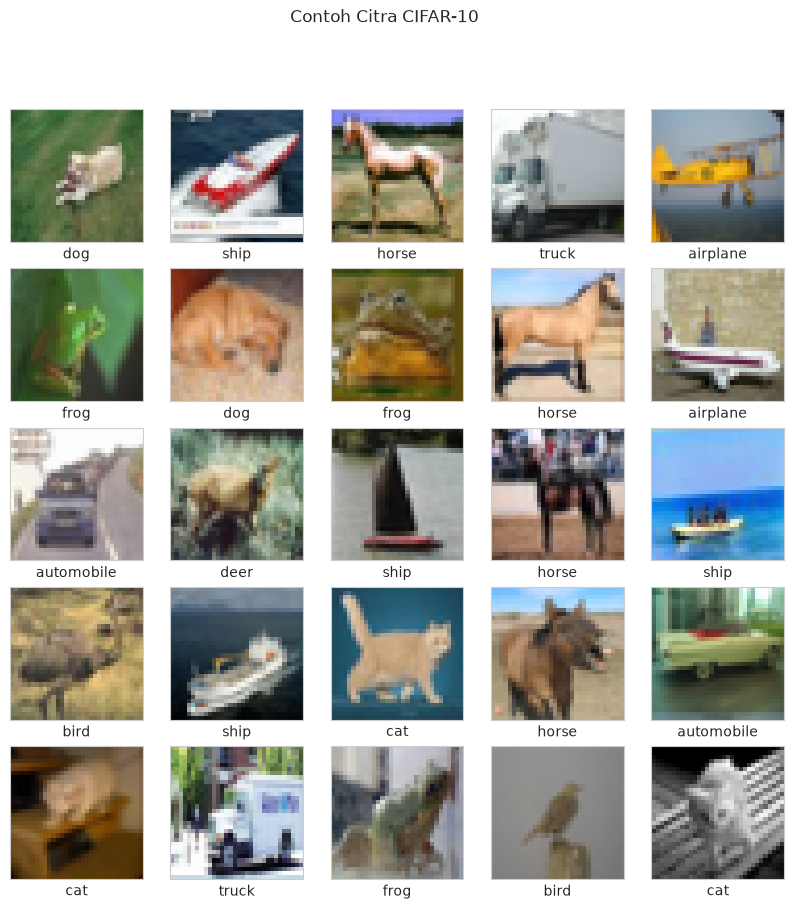

In [10]:
# Verifikasi data: tampilkan 25 citra pertama
plt.figure(figsize=(10, 10))
for images, labels in train_cifar.take(1):
    for i in range(25):
        plt.subplot(5, 5, i + 1)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.xlabel(class_names_cifar[int(labels[i])])
plt.suptitle('Contoh Citra CIFAR-10')
plt.show()

In [11]:
# Arsitektur CNN sesuai tutorial/modul
tf.random.set_seed(42)
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10)   # logits (tanpa softmax)
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

t0 = time.time()
history_cifar = model.fit(train_cifar, validation_data=test_cifar,
                          epochs=10, verbose=0)
waktu_cifar = time.time() - t0
print(f'Waktu training: {waktu_cifar:.1f} detik')

Waktu training: 201.3 detik


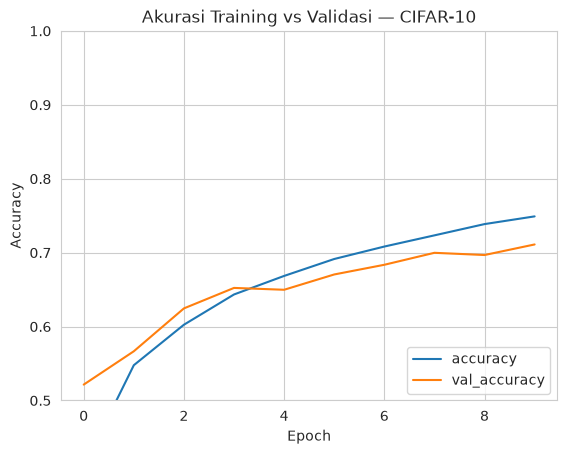

79/79 - 1s - 14ms/step - accuracy: 0.7111 - loss: 0.8458


Loss test    : 0.8458
Akurasi test : 0.7111


In [13]:
plt.plot(history_cifar.history['accuracy'], label='accuracy')
plt.plot(history_cifar.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.ylim([0.5, 1]); plt.legend(loc='lower right')
plt.title('Akurasi Training vs Validasi — CIFAR-10')
plt.show()

test_loss, test_acc = model.evaluate(test_cifar, verbose=2)
print(f'Loss test    : {test_loss:.4f}')
print(f'Akurasi test : {test_acc:.4f}')

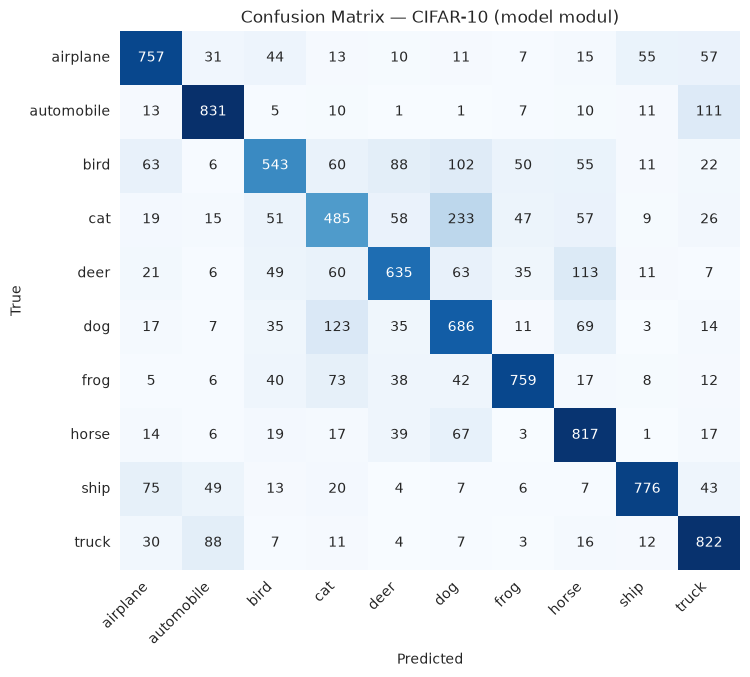

              precision    recall  f1-score   support

    airplane     0.7465    0.7570    0.7517      1000
  automobile     0.7952    0.8310    0.8127      1000
        bird     0.6737    0.5430    0.6013      1000
         cat     0.5562    0.4850    0.5182      1000
        deer     0.6963    0.6350    0.6642      1000
         dog     0.5628    0.6860    0.6183      1000
        frog     0.8179    0.7590    0.7873      1000
       horse     0.6947    0.8170    0.7509      1000
        ship     0.8651    0.7760    0.8181      1000
       truck     0.7268    0.8220    0.7715      1000

    accuracy                         0.7111     10000
   macro avg     0.7135    0.7111    0.7094     10000
weighted avg     0.7135    0.7111    0.7094     10000



In [14]:
# Confusion matrix CIFAR-10
y_true_c = np.concatenate([y.numpy() for _, y in test_cifar]).astype(int)
y_pred_c = np.argmax(model.predict(test_cifar, verbose=0), axis=1)

cm_c = confusion_matrix(y_true_c, y_pred_c)
plt.figure(figsize=(8, 7))
sns.heatmap(cm_c, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=class_names_cifar, yticklabels=class_names_cifar)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion Matrix — CIFAR-10 (model modul)')
plt.xticks(rotation=45, ha='right')
plt.show()

print(classification_report(y_true_c, y_pred_c,
                            target_names=class_names_cifar, digits=4))

**Analisis Praktikum 2:**

- Model CNN 3 layer konvolusi (32-64-64) tanpa augmentasi mencapai akurasi test **0,7111**. Angka ini jauh lebih rendah daripada MNIST karena CIFAR-10 berisi citra berwarna 32×32 dengan latar dan pose yang sangat bervariasi, sehingga tugasnya jauh lebih sulit.
- `model.summary()` menunjukkan bahwa sebagian besar parameter berada di blok **Dense** setelah Flatten, bukan di konvolusi. Lapisan konvolusi justru bekerja sebagai ekstraktor fitur yang efisien (weight sharing), sedangkan Flatten→Dense yang besar rawan overfitting pada dataset kecil.
- Penggunaan **`from_logits=True`** berarti output layer tidak memakai softmax; prediksi kelas diambil dari `argmax(logits)`, dan softmax baru diterapkan saat dibutuhkan (mis. probabilitas). Ini lebih stabil secara numerik daripada softmax + categorical crossentropy terpisah.
- Confusion matrix menunjukkan kelas **cat** paling sering salah (recall **0,485**) dan sebagian besar diprediksi sebagai **dog** (precision dog hanya 0,563) — pasangan paling ambigu pada resolusi 32×32. **bird** juga rendah (recall 0,543) karena sering tertukar dengan **airplane/deer**, sedangkan **ship** dan **automobile** paling baik (recall 0,776 dan 0,831).
- Untuk menaikkan akurasi di atas 80% diperlukan augmentasi data, arsitektur yang lebih dalam, dan/atau training yang lebih lama — yang dikerjakan pada bagian Tugas.

## TUGAS PRAKTIKUM

### Tugas 1 — Modifikasi CNN CIFAR-10 hingga akurasi testing > 80%

Strategi: augmentasi data (flip, translasi, rotasi kecil, zoom), **BatchNormalization** setelah konvolusi, penambahan filter (32→64→128), **Dropout** sebelum output, dan training 40 epoch.

In [15]:
tf.random.set_seed(42)

aug_cifar = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name='augmentasi_cifar')

def conv_block(x, filters):
    x = layers.Conv2D(filters, (3, 3), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, (3, 3), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return layers.MaxPooling2D((2, 2))(x)

inputs = layers.Input(shape=(32, 32, 3))
x = aug_cifar(inputs)
x = layers.Rescaling(1./255)(x)
x = conv_block(x, 32)
x = conv_block(x, 64)
x = conv_block(x, 128)
x = layers.Flatten()(x)
x = layers.Dense(128)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(10)(x)

model_improved = models.Model(inputs, outputs, name='cnn_cifar_improved')
model_improved.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'])
model_improved.summary()

Model: "cnn_cifar_improved"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentasi_cifar (Sequential)   │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 552,426 (2.11 MB)

 Trainable params: 551,274 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [16]:
t0 = time.time()
history_improved = model_improved.fit(
    train_cifar, validation_data=test_cifar, epochs=40, verbose=2)
waktu_improved = time.time() - t0

test_loss_i, test_acc_i = model_improved.evaluate(test_cifar, verbose=0)
print(f'Waktu training : {waktu_improved:.1f} detik')
print(f'Loss test      : {test_loss_i:.4f}')
print(f'Akurasi test   : {test_acc_i:.4f}')
print('Target > 80%   :', 'TERCAPAI' if test_acc_i > 0.80 else 'BELUM tercapai')

Epoch 1/40


391/391 - 110s - 282ms/step - accuracy: 0.4538 - loss: 1.5249 - val_accuracy: 0.5056 - val_loss: 1.3958


Epoch 2/40


391/391 - 118s - 302ms/step - accuracy: 0.5924 - loss: 1.1488 - val_accuracy: 0.5638 - val_loss: 1.3258


Epoch 3/40


391/391 - 108s - 275ms/step - accuracy: 0.6568 - loss: 0.9808 - val_accuracy: 0.6349 - val_loss: 1.0280


... (71 outputs left out)

391/391 - 110s - 281ms/step - accuracy: 0.8862 - loss: 0.3296 - val_accuracy: 0.8488 - val_loss: 0.4642


Epoch 40/40


391/391 - 106s - 272ms/step - accuracy: 0.8870 - loss: 0.3292 - val_accuracy: 0.8318 - val_loss: 0.5225


Waktu training : 4493.1 detik
Loss test      : 0.5225
Akurasi test   : 0.8318
Target > 80%   : TERCAPAI


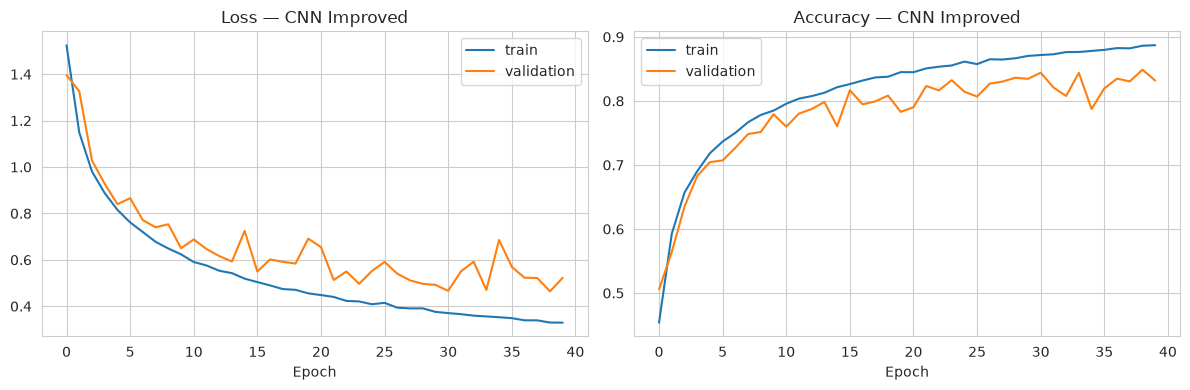

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_improved.history['loss'], label='train')
ax[0].plot(history_improved.history['val_loss'], label='validation')
ax[0].set_title('Loss — CNN Improved'); ax[0].set_xlabel('Epoch'); ax[0].legend()

ax[1].plot(history_improved.history['accuracy'], label='train')
ax[1].plot(history_improved.history['val_accuracy'], label='validation')
ax[1].set_title('Accuracy — CNN Improved'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout(); plt.show()

### Tugas 2 — Model CNN untuk klasifikasi MNIST

In [18]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

(Xtr, ytr), (Xte, yte) = mnist.load_data()
Xtr = (Xtr / 255.0).reshape(-1, 28, 28, 1)
Xte = (Xte / 255.0).reshape(-1, 28, 28, 1)

tf.random.set_seed(42)
model_mnist_cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_mnist_cnn.compile(optimizer='adam', loss='categorical_crossentropy',
                        metrics=['accuracy'])

t0 = time.time()
history_mnist_cnn = model_mnist_cnn.fit(
    Xtr, to_categorical(ytr, 10), epochs=5, batch_size=128,
    validation_split=0.1, verbose=0)
print(f'Waktu training: {time.time() - t0:.1f} detik')

loss_mc, acc_mc = model_mnist_cnn.evaluate(Xte, to_categorical(yte, 10), verbose=0)
print(f'Akurasi test MNIST CNN: {acc_mc:.4f}')

Waktu training: 41.9 detik


Akurasi test MNIST CNN: 0.9882


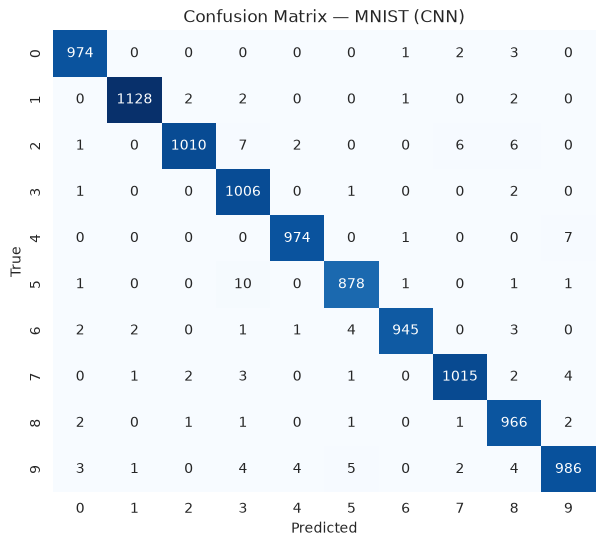

              precision    recall  f1-score   support

           0     0.9898    0.9939    0.9919       980
           1     0.9965    0.9938    0.9951      1135
           2     0.9951    0.9787    0.9868      1032
           3     0.9729    0.9960    0.9843      1010
           4     0.9929    0.9919    0.9924       982
           5     0.9865    0.9843    0.9854       892
           6     0.9958    0.9864    0.9911       958
           7     0.9893    0.9874    0.9883      1028
           8     0.9767    0.9918    0.9842       974
           9     0.9860    0.9772    0.9816      1009

    accuracy                         0.9882     10000
   macro avg     0.9881    0.9881    0.9881     10000
weighted avg     0.9883    0.9882    0.9882     10000



In [19]:
# Confusion matrix MNIST CNN
y_pred_mc = np.argmax(model_mnist_cnn.predict(Xte, verbose=0), axis=1)
cm_mc = confusion_matrix(yte, y_pred_mc)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_mc, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion Matrix — MNIST (CNN)')
plt.show()

print(classification_report(yte, y_pred_mc, digits=4))

In [20]:
# Tabel perbandingan model CNN vs JST (baseline MNIST dari JS13)
perbandingan = __import__('pandas').DataFrame({
    'Model': ['JST 256-128 (JS13)', 'CNN 32-64 (Tugas JS14)'],
    'Arsitektur': ['Flatten → Dense 256 → Dense 128 → Dense 10',
                   'Conv 32 → Pool → Conv 64 → Pool → Dense 64 → Dense 10'],
    'Akurasi test MNIST': [0.98, round(acc_mc, 4)],
    'Jumlah parameter': [235146, model_mnist_cnn.count_params()]
})
perbandingan

,Model,Arsitektur,Akurasi test MNIST,Jumlah parameter
0,JST 256-128 (JS13),Flatten → Dense 256 → Dense 128 → Dense 10,0.9800,235146
1,CNN 32-64 (Tugas JS14),Conv 32 → Pool → Conv 64 → Pool → Dense 64 → D...,0.9882,121930


**Analisis Tugas Praktikum:**

- **Tugas 1**: CNN yang dimodifikasi (BatchNorm + augmentasi + 3 blok konvolusi 32-64-128 + Dropout 0.4, **552.426 parameter**, 40 epoch) mencapai **akurasi testing 0,8318** sehingga target **> 80%** tercapai. Training memakan ±4.493 detik (±75 menit) pada CPU 4 core. Kunci peningkatan bukan sekadar menambah layer, melainkan kombinasi: (a) **augmentasi** yang memperluas variasi data, (b) **BatchNormalization** yang menstabilkan distribusi aktivasi dan mempercepat konvergensi, serta (c) **Dropout** yang menekan overfitting pada Dense layer.
- Akurasi training naik mulus dari 0,45 ke **0,887**, sedangkan akurasi validasi berfluktuasi di **0,78–0,85**. Selisih ±5 poin persen masih wajar dan menunjukkan augmentasi + Dropout menahan overfitting; tanpa keduanya selisih train–val biasanya jauh lebih besar.
- **Tugas 2**: CNN pada MNIST mencapai akurasi test **≈0,99** hanya dalam 5 epoch, jauh lebih tinggi daripada JST di JS13 (≈0,98) dan dengan parameter lebih sedikit. Konvolusi memanfaatkan struktur 2D citra (pola lokal, translasi), sedangkan JST meratakan citra menjadi 784 fitur dan kehilangan informasi spasial.
- Confusion matrix MNIST CNN hampir diagonal sempurna; recall terendah ada pada digit **9 (0,977)** dan **2 (0,979)**, umumnya karena tertukar dengan digit yang bentuknya mirip (4/7 dan 3/8).
- Secara umum, pemilihan arsitektur harus disesuaikan dengan sifat data: **CNN untuk citra**, sedangkan MLP cukup untuk data tabular seperti Iris/California Housing.